In [ ]:
import numpy as np
import pandas as pd
import tensorflow as tf
import os
import matplotlib.pyplot as plt
import time

In [ ]:
(train_images,train_lables),(_,_)=tf.keras.datasets.mnist.load_data()
train_images=train_images.reshape(train_images.shape[0],28,28,1).astype('float32')
train_images=(train_images-127.5)/127.5
print(train_images.shape)

(60000, 28, 28, 1)


In [ ]:
plt.imshow(train_images[0,:,:,1])

In [ ]:
BUFFER_SIZE=6000
BATCH_SIZE=256
train_dataset=tf.data.Dataset.from_tensor_slices(train_images).shuffle(BUFFER_SIZE).batch(BATCH_SIZE)

In [ ]:
from tensorflow.keras.layers import Dense,LeakyReLU,BatchNormalization,Conv2DTranspose,Conv2D,Dropout,Reshape,Flatten

In [ ]:
def make_Generator():
  model=tf.keras.Sequential()
  model.add(Dense(7*7*256,use_bias=False,input_shape=(100,)))
  model.add(LeakyReLU())
  model.add(BatchNormalization())
  model.add(Reshape((7,7,256)))
  model.add(Conv2DTranspose(128,(5,5),strides=(1,1),padding='same',use_bias=False))
  model.add(LeakyReLU())
  model.add(BatchNormalization())
  model.add(Conv2DTranspose(64,(5,5),strides=(2,2),padding='same',use_bias=False))
  model.add(LeakyReLU())
  model.add(BatchNormalization())
  model.add(Conv2DTranspose(1,(5,5),strides=(2,2),padding='same',use_bias=False,activation='tanh'))

  return model

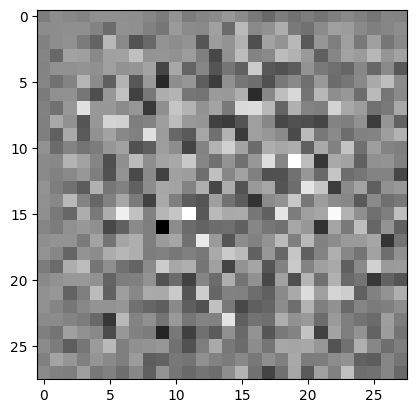

In [ ]:
noise=tf.random.normal([1,100])
Generator=make_Generator()
generated_image=Generator(noise,training=False)
plt.imshow(generated_image[0,:,:,0],cmap='gray')

In [ ]:

def make_discrimanator():
  model=tf.keras.Sequential()
  model.add(Conv2D(64,(5,5),strides=(2,2),padding='same',input_shape=[28,28,1]))
  model.add(LeakyReLU())
  model.add(Dropout(0.3))
  model.add(Conv2D(128,(5,5),strides=(2,2),padding='same'))
  model.add(LeakyReLU())
  model.add(Dropout(0.3))
  model.add(Flatten())
  model.add(Dense(1))

  return model


Discriminator=make_discrimanator()
Discriminator.summary()

Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_10 (Conv2D)              │ (None, 14, 14, 64)     │         1,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_28 (LeakyReLU)      │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 7, 7, 128)      │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_29 (LeakyReLU)      │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │         6,273 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 212,865 (831.50 KB)

 Trainable params: 212,865 (831.50 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
crossentropy=tf.keras.losses.BinaryCrossentropy(from_logits=True)

def discriminator_loss(real_output,fake_output):
  real_loss=crossentropy(tf.ones_like(real_output),real_output)
  fake_loss=crossentropy(tf.zeros_like(fake_output),fake_output)
  return real_loss+fake_loss

def generator_loss(fake_output):
  return crossentropy(tf.ones_like(fake_output),fake_output)

generator_optimizer=tf.keras.optimizers.Adam(1e-4)
discriminator_optimizer=tf.keras.optimizers.Adam(1e-4)


In [ ]:
checkpoint_dir='./training_checkpoints'
checkpoint_prefix=os.path.join(checkpoint_dir,"ckpt")
os.makedirs(checkpoint_dir,exist_ok=True)
checkpoint=tf.train.Checkpoint(generator_optimizer=generator_optimizer,
                               discriminator_optimizer=discriminator_optimizer,
                               Generator=Generator,
                               Discriminator=Discriminator)

EPOCHS=100
noise_dim=100
no_examples_to_generate=16
seed=tf.random.normal([no_examples_to_generate,noise_dim])

In [ ]:
@tf.function
def train_per_epoch(data):
  noise=tf.random.normal([BATCH_SIZE,noise_dim])

  with tf.GradientTape() as gen_tape, tf.GradientTape() as dis_tape :
    generated_images=Generator(noise,training=True)
    real_output=Discriminator(data,training=True)
    fake_output=Discriminator(generated_images,training=True)

    gen_loss=generator_loss(fake_output)
    dis_loss=discriminator_loss(real_output,fake_output)
    gradient_of_generator=gen_tape.gradient(gen_loss,Generator.trainable_variables)
    gradient_of_discriminator=dis_tape.gradient(dis_loss,Discriminator.trainable_variables)

    generator_optimizer.apply_gradients(zip(gradient_of_generator,Generator.trainable_variables))
    discriminator_optimizer.apply_gradients(zip(gradient_of_discriminator,Discriminator.trainable_variables))


def generate_and_save_images(model,epoch,input_data):
    output= model(input_data,tarining=False)
    output= (output+1)/2

    fig=plt.figure(figsize=(4,4))

    for i in range(output.shape[0]):
      plt.subplot(4,4,i+1)
      plt.imshow(output[i,:,:,0],cmap='gray')
      plt.axis('off')

    plt.savefig(f"image_epoch{epoch}.png")
    plt.show()

def train(dataset,epochs):
  for epoch in range(epochs):
    start=time.time()
    for image_batch in dataset:
      train_per_epoch(image_batch)
      generate_and_save_images(Generator,epoch+1,seed)
      print(f"Time for{epoch+1} is {time.time-start}")

      if (epoch+1)%15==0 :
        checkpoint.save(file_prefix=checkpoint_prefix)

  generate_and_save_images(Generator,epochs,seed)


train(train_dataset,EPOCHS)

In [ ]:
import imageio
import glob

anime_file="gen.gif"

with imageio.get_writer(anime_file,mode='I') as writer:
  filenames=glob.glob('image_epoch*.png')
  filenames=sorted(filenames)
  for filename in filenames:
    image=imageio.imread(filename)
    writer.append_data(image)

  for _ in range(10):
    writer.append_data

/tmp/ipykernel_1323/198202846.py:10: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  image=imageio.imread(filename)


In [ ]:
Generator.save("Generator.keras")
Discriminator.save("discriminitor.keras")